# Audio Noise Reduction: Compatible Mixture

This notebook compares direct sample-by-sample addition with a version where the noise is resampled to the clean speech sampling rate first. The original notebook is not changed.

A sample rate defines the time represented by each sample. Direct addition assumes that sample `i` in each signal represents the same instant. Here the clean speech and noise are recorded at different rates, so directly adding their samples and playing the result at the speech rate changes the noise's effective speed and pitch. Resampling gives both signals a shared time grid before alignment and addition.

The baseline below deliberately reproduces direct addition for comparison. Its noise segment is selected by sample count and then interpreted at the speech rate; it is not a physically correct mixture. The compatible mixture uses a segment beginning 2 seconds into the noise recording and scales it to the selected target SNR.

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import IPython.display as ipd

## Load and prepare the recordings

Both inputs are converted to mono floating-point signals. Integer PCM values are normalized according to their dtype; floating-point inputs are retained as floating point.

In [95]:
def to_mono_float(audio):
    audio = np.asarray(audio)
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    elif audio.ndim != 1:
        raise ValueError(f"Expected mono or stereo audio; got shape {audio.shape}")

    if np.issubdtype(audio.dtype, np.integer):
        limits = np.iinfo(audio.dtype)
        audio = audio.astype(np.float64)
        if limits.min < 0:
            audio /= max(abs(limits.min), limits.max)
        else:
            midpoint = (limits.max + 1) / 2
            audio = (audio - midpoint) / midpoint
    else:
        audio = audio.astype(np.float64)

    peak = np.max(np.abs(audio))
    if peak == 0:
        raise ValueError("Audio recording is silent")
    return audio / peak


fs_clean, clean_raw = wavfile.read("./audio/clean_speech.wav")
fs_noise, noise_raw = wavfile.read("./audio/noise_recording.wav")
clean = to_mono_float(clean_raw)
noise_original = to_mono_float(noise_raw)

print(f"Clean speech: {fs_clean} Hz, {len(clean)} samples ({len(clean) / fs_clean:.2f} s)")
print(f"Noise:        {fs_noise} Hz, {len(noise_original)} samples ({len(noise_original) / fs_noise:.2f} s)")

Clean speech: 16000 Hz, 172343 samples (10.77 s)
Noise:        44100 Hz, 587001 samples (13.31 s)


## Create the intentionally incompatible baseline

This baseline takes the same number of noise samples as speech samples, adds them directly, and plays the result at the speech sampling rate. Because those noise samples were captured at a different rate, their timing and pitch are altered in this demonstration.

In [96]:
noise_start_seconds = 2.0
baseline_start = int(round(noise_start_seconds * fs_noise))
baseline_stop = baseline_start + len(clean)
if baseline_stop > len(noise_original):
    raise ValueError("Noise recording is too short for the baseline segment")

baseline_noise = noise_original[baseline_start:baseline_stop]
incompatible_mixture = clean + baseline_noise
baseline_noise_power = np.mean(baseline_noise ** 2)
baseline_snr_db = 10 * np.log10(np.mean(clean ** 2) / baseline_noise_power)

## Resample, align, and mix compatibly

`resample_poly` converts the noise to the speech sampling rate. We then take a segment starting at the same 2-second point, but measured on the resampled time grid, and match the noise RMS to a chosen target SNR. Change `target_snr_db` to experiment with different noise levels.

In [97]:
rate_gcd = np.gcd(fs_clean, fs_noise)
noise_resampled = signal.resample_poly(
    noise_original,
    int(fs_clean // rate_gcd),
    int(fs_noise // rate_gcd)
)

compatible_start = int(round(noise_start_seconds * fs_clean))
compatible_stop = compatible_start + len(clean)
if compatible_stop > len(noise_resampled):
    raise ValueError("Noise recording is too short for the compatible segment")
compatible_noise = noise_resampled[compatible_start:compatible_stop].copy()
noise_rms = np.sqrt(np.mean(compatible_noise ** 2))
if noise_rms == 0:
    raise ValueError("Selected noise segment is silent")

target_snr_db = 5.0
clean_rms = np.sqrt(np.mean(clean ** 2))
compatible_noise *= clean_rms / (noise_rms * 10 ** (target_snr_db / 20))
compatible_mixture = clean + compatible_noise
compatible_snr_db = 10 * np.log10(
    np.mean(clean ** 2) / np.mean((compatible_mixture - clean) ** 2)
)

print(f"Noise sampling rate: {fs_noise} Hz -> {fs_clean} Hz")
print(f"Baseline samples: {len(incompatible_mixture)}")
print(f"Compatible samples: {len(compatible_mixture)}")
print(f"Baseline mixture SNR estimate: {baseline_snr_db:.2f} dB")
print(f"Compatible mixture SNR: {compatible_snr_db:.2f} dB (target {target_snr_db:.2f} dB)")

Noise sampling rate: 44100 Hz -> 16000 Hz
Baseline samples: 172343
Compatible samples: 172343
Baseline mixture SNR estimate: 5.16 dB
Compatible mixture SNR: 5.00 dB (target 5.00 dB)


## Compare waveforms and listen

The sample counts and displayed time axes match. The baseline and compatible mixtures can be listened to separately; the playback widget may normalize audio for playback if its peak exceeds the normal range.

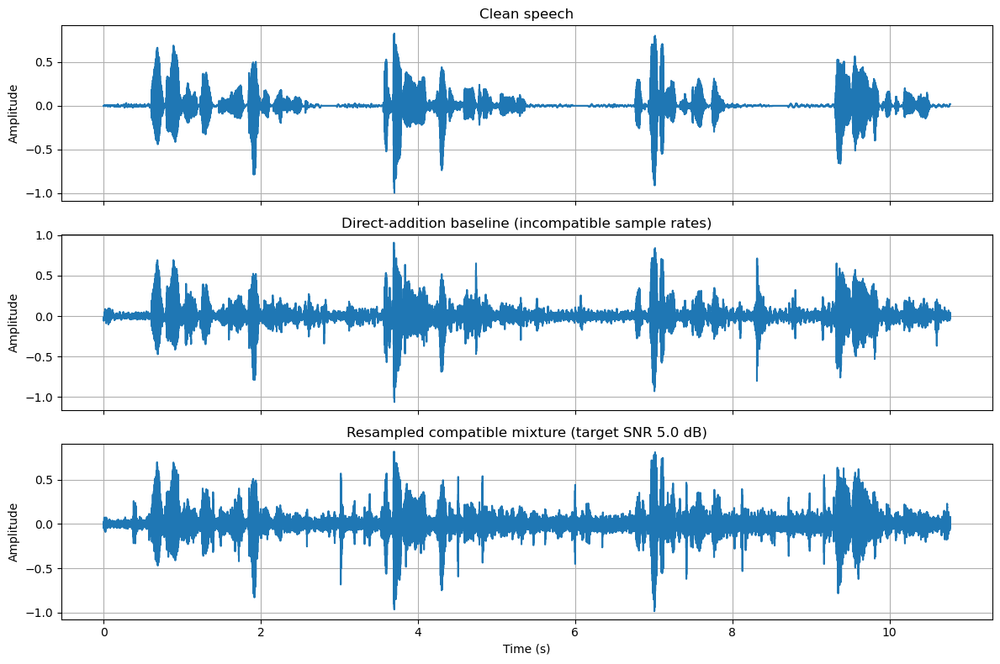

Direct-addition baseline:


Resampled compatible mixture:


In [98]:
time = np.arange(len(clean)) / fs_clean
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(time, clean)
axes[0].set_title("Clean speech")
axes[1].plot(time, incompatible_mixture)
axes[1].set_title("Direct-addition baseline (incompatible sample rates)")
axes[2].plot(time, compatible_mixture)
axes[2].set_title(f"Resampled compatible mixture (target SNR {target_snr_db:.1f} dB)")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(True)
plt.tight_layout()
plt.show()

print("Direct-addition baseline:")
ipd.display(ipd.Audio(incompatible_mixture, rate=fs_clean))
print("Resampled compatible mixture:")
ipd.display(ipd.Audio(compatible_mixture, rate=fs_clean))

## Noise-reduction pipeline

This section follows the project plan: inspect the noisy signal and noise spectrum, apply zero-phase FIR and IIR band-pass filters as simple baselines, then apply spectral subtraction and a Wiener gain using a noise estimate. The clean speech is a known reference, so SNR can be measured objectively.

The passband starts near 70 Hz and ends at 7.5 kHz, consistent with the project plan's suggested high-pass/low-pass baseline and the 16 kHz sample rate (8 kHz Nyquist). The noise spectrum overlaps speech, so a band-pass filter is expected to help only modestly; the STFT methods are intended to reduce more of the in-band noise.

The practical spectral methods estimate average noise power from the separate noise-only recording, scaled to the noise level used in the mixture. The exact added noise component is also used as an **oracle reference** for an upper-bound comparison; that exact reference would not be available in a real recording.

Course references: [Week 6 spectrum/FFT](../Documents/week6_spectrum_reading_fft_and_leakage.pdf), [Week 7 FIR](../Documents/week7_FIR.pdf), and [Week 8 IIR](../Documents/week8_zero_padding_feedback_and_iir.pdf). The full method sequence is in [projectPlan.md](projectPlan.md).

### 1. Inspect the noisy signal and identify noise bands

Compare the clean speech, noisy mixture, and separate noise recording in the time and frequency domains. The band-energy fractions below help assess what a simple band-pass filter can remove; speech and noise overlapping in frequency will require spectral denoising.

Noise PSD power by candidate filter band:
  0-70 Hz: 0.000510092 (24.32% of estimated noise power)
  70-7500 Hz: 0.00145155 (69.21% of estimated noise power)
  7500-8000 Hz: 1.21106e-05 (0.58% of estimated noise power)


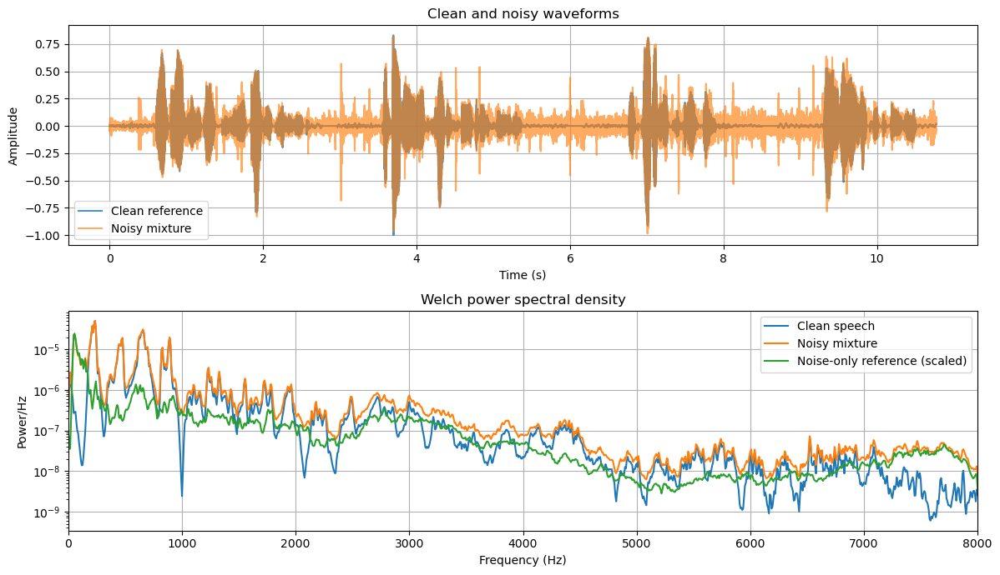

In [99]:
# Welch PSD provides a stable view of the broad frequency content.
plot_nperseg = min(2048, len(clean))
f_clean_psd, clean_psd = signal.welch(clean, fs=fs_clean, window="hann", nperseg=plot_nperseg)
f_mix_psd, mix_psd = signal.welch(compatible_mixture, fs=fs_clean, window="hann", nperseg=plot_nperseg)

# Scale a separate noise-only recording to the mixture noise RMS for an apples-to-apples PSD plot.
noise_gain = np.sqrt(np.mean(compatible_noise ** 2)) / np.sqrt(np.mean(noise_resampled ** 2))
noise_profile_signal = noise_resampled * noise_gain
f_noise_psd, noise_psd = signal.welch(noise_profile_signal, fs=fs_clean, window="hann", nperseg=plot_nperseg)

nyquist = fs_clean / 2
band_edges = (0.0, 70.0, 7500.0, nyquist)
print("Noise PSD power by candidate filter band:")
for lower, upper in zip(band_edges[:-1], band_edges[1:]):
    band = (f_noise_psd >= lower) & (f_noise_psd < upper)
    power = np.trapezoid(noise_psd[band], f_noise_psd[band]) if np.count_nonzero(band) > 1 else 0.0
    total = np.trapezoid(noise_psd, f_noise_psd)
    print(f"  {lower:.0f}-{upper:.0f} Hz: {power:.6g} ({100 * power / total:.2f}% of estimated noise power)")

plot_time = np.arange(len(clean)) / fs_clean
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(plot_time, clean, label="Clean reference", alpha=0.8)
axes[0].plot(plot_time, compatible_mixture, label="Noisy mixture", alpha=0.65)
axes[0].set_title("Clean and noisy waveforms")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

axes[1].semilogy(f_clean_psd, clean_psd + 1e-15, label="Clean speech")
axes[1].semilogy(f_mix_psd, mix_psd + 1e-15, label="Noisy mixture")
axes[1].semilogy(f_noise_psd, noise_psd + 1e-15, label="Noise-only reference (scaled)")
axes[1].set_xlim(0, nyquist)
axes[1].set_title("Welch power spectral density")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Power/Hz")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()



### 2. FIR and IIR baseline filters

The course examples introduce FIR design with `firwin`, IIR Butterworth design, and frequency-response inspection with `freqz`. Both filters below use a 70 Hz to 7.5 kHz passband and forward-backward filtering (`filtfilt` / `sosfiltfilt`) to avoid a net phase delay. They are baselines, not expected to remove noise that overlaps speech.

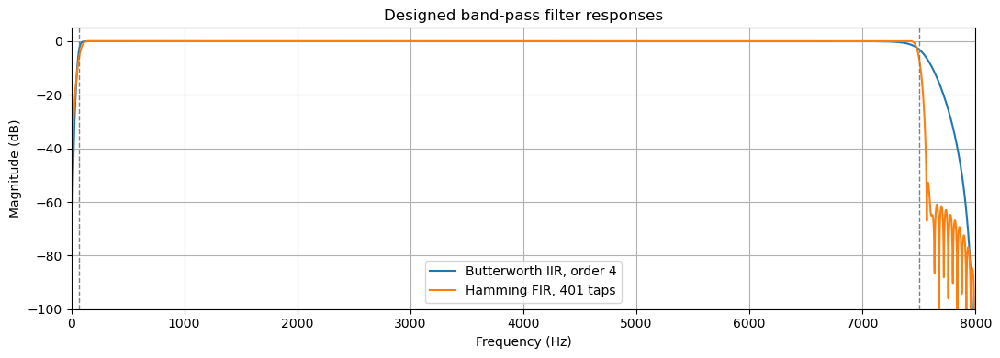

In [100]:
low_cutoff_hz = 70.0
high_cutoff_hz = 7500.0
if not (0 < low_cutoff_hz < high_cutoff_hz < fs_clean / 2):
    raise ValueError("Filter cutoffs must be positive, ordered, and below Nyquist")

# Butterworth IIR band-pass, applied as stable second-order sections.
iir_order = 4
iir_sos = signal.butter(
    iir_order,
    [low_cutoff_hz, high_cutoff_hz],
    btype="bandpass",
    fs=fs_clean,
    output="sos",
)
iir_filtered = signal.sosfiltfilt(iir_sos, compatible_mixture)

# Windowed-sinc FIR band-pass. filtfilt removes the linear-phase delay.
fir_numtaps = 401
fir_taps = signal.firwin(
    numtaps=fir_numtaps,
    cutoff=[low_cutoff_hz, high_cutoff_hz],
    pass_zero="bandpass",
    fs=fs_clean,
    window="hamming",
)
fir_filtered = signal.filtfilt(fir_taps, [1.0], compatible_mixture)

f_iir_response, h_iir_response = signal.sosfreqz(iir_sos, worN=4096, fs=fs_clean)
f_fir_response, h_fir_response = signal.freqz(fir_taps, worN=4096, fs=fs_clean)
plt.figure(figsize=(11, 4))
plt.plot(f_iir_response, 20 * np.log10(np.maximum(np.abs(h_iir_response), 1e-8)), label=f"Butterworth IIR, order {iir_order}")
plt.plot(f_fir_response, 20 * np.log10(np.maximum(np.abs(h_fir_response), 1e-8)), label=f"Hamming FIR, {fir_numtaps} taps")
plt.axvline(low_cutoff_hz, color="gray", linestyle="--", linewidth=1)
plt.axvline(high_cutoff_hz, color="gray", linestyle="--", linewidth=1)
plt.xlim(0, fs_clean / 2)
plt.ylim(-100, 5)
plt.title("Designed band-pass filter responses")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### 3. STFT spectral subtraction and Wiener filtering

Use a 512-sample Hann window (32 ms at 16 kHz) with a 128-sample hop (75% overlap). The realistic profile averages noise power over the separate noise-only recording. Spectral subtraction reduces the estimated noise magnitude with an over-subtraction factor and spectral floor; the Wiener method estimates a soft gain between zero and one. The oracle variants use the exact injected noise STFT only as a controlled upper-bound comparison.

In [101]:
from scipy.ndimage import median_filter

frame_length = 512
hop_length = 128
frame_overlap = frame_length - hop_length
window_name = "hann"

freq_stft, time_stft, noisy_stft = signal.stft(
    compatible_mixture,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary="zeros",
    padded=True,
)
_, _, noise_profile_stft = signal.stft(
    noise_profile_signal,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary="zeros",
    padded=True,
)
_, _, oracle_noise_stft = signal.stft(
    compatible_noise,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary="zeros",
    padded=True,
)

noisy_magnitude = np.abs(noisy_stft)
noisy_phase = np.exp(1j * np.angle(noisy_stft))
noise_profile_power = np.mean(np.abs(noise_profile_stft) ** 2, axis=1, keepdims=True)
noise_profile_magnitude = np.sqrt(noise_profile_power)
oracle_noise_magnitude = np.abs(oracle_noise_stft)
oracle_noise_power = oracle_noise_magnitude ** 2

# Spectral subtraction using the averaged noise-only recording profile.
ss_alpha = 1.2
ss_floor = 0.05
estimated_clean_magnitude = np.maximum(
    noisy_magnitude - ss_alpha * noise_profile_magnitude,
    ss_floor * noise_profile_magnitude,
)
_, spectral_subtraction = signal.istft(
    estimated_clean_magnitude * noisy_phase,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary=True,
)
spectral_subtraction = spectral_subtraction[:len(clean)]

# Wiener gain using the same averaged estimate, smoothed to reduce isolated artifacts.
noisy_power = noisy_magnitude ** 2
estimated_wiener_gain = np.sqrt(
    np.maximum(noisy_power - noise_profile_power, 0.0) / (noisy_power + 1e-12)
)
estimated_wiener_gain = median_filter(estimated_wiener_gain, size=(3, 3))
estimated_wiener_gain = np.maximum(estimated_wiener_gain, 0.05)
_, wiener_filtered = signal.istft(
    noisy_magnitude * estimated_wiener_gain * noisy_phase,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary=True,
)
wiener_filtered = wiener_filtered[:len(clean)]

# Oracle spectral subtraction: exact injected noise is available only in this simulation.
oracle_clean_magnitude = np.maximum(
    noisy_magnitude - ss_alpha * oracle_noise_magnitude,
    ss_floor * oracle_noise_magnitude,
)
_, oracle_spectral_subtraction = signal.istft(
    oracle_clean_magnitude * noisy_phase,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary=True,
)
oracle_spectral_subtraction = oracle_spectral_subtraction[:len(clean)]

# Oracle Wiener gain gives an upper-bound reference, not a deployable denoiser.
oracle_wiener_gain = np.sqrt(
    np.maximum(noisy_power - oracle_noise_power, 0.0) / (noisy_power + 1e-12)
)
oracle_wiener_gain = median_filter(oracle_wiener_gain, size=(3, 3))
oracle_wiener_gain = np.maximum(oracle_wiener_gain, 0.05)
_, oracle_wiener = signal.istft(
    noisy_magnitude * oracle_wiener_gain * noisy_phase,
    fs=fs_clean,
    window=window_name,
    nperseg=frame_length,
    noverlap=frame_overlap,
    boundary=True,
)
oracle_wiener = oracle_wiener[:len(clean)]

for name, result in {
    "IIR": iir_filtered,
    "FIR": fir_filtered,
    "Spectral subtraction": spectral_subtraction,
    "Wiener": wiener_filtered,
    "Oracle spectral subtraction": oracle_spectral_subtraction,
    "Oracle Wiener": oracle_wiener,
}.items():
    if len(result) != len(clean) or not np.all(np.isfinite(result)):
        raise ValueError(f"{name} output has an invalid length or non-finite samples")

### 4. Before/after evaluation

SNR is computed against the known clean reference. SNR improvement is output SNR minus the measured input SNR. The oracle results use the exact noise waveform and should be interpreted only as a best-case benchmark. Use the plots and listening comparisons too: a higher SNR alone does not guarantee better perceived speech quality.

Measured input SNR: 5.00 dB
Method                                      Output SNR     Improvement
------------------------------------------------------------------------
Noisy input                                      5.00 dB      +0.00 dB
IIR band-pass                                    6.59 dB      +1.59 dB
FIR band-pass                                    7.01 dB      +2.01 dB
Spectral subtraction (estimated profile)        10.52 dB      +5.52 dB
Wiener (estimated profile)                       8.19 dB      +3.19 dB
Oracle spectral subtraction                     15.48 dB     +10.48 dB
Oracle Wiener                                   15.47 dB     +10.47 dB


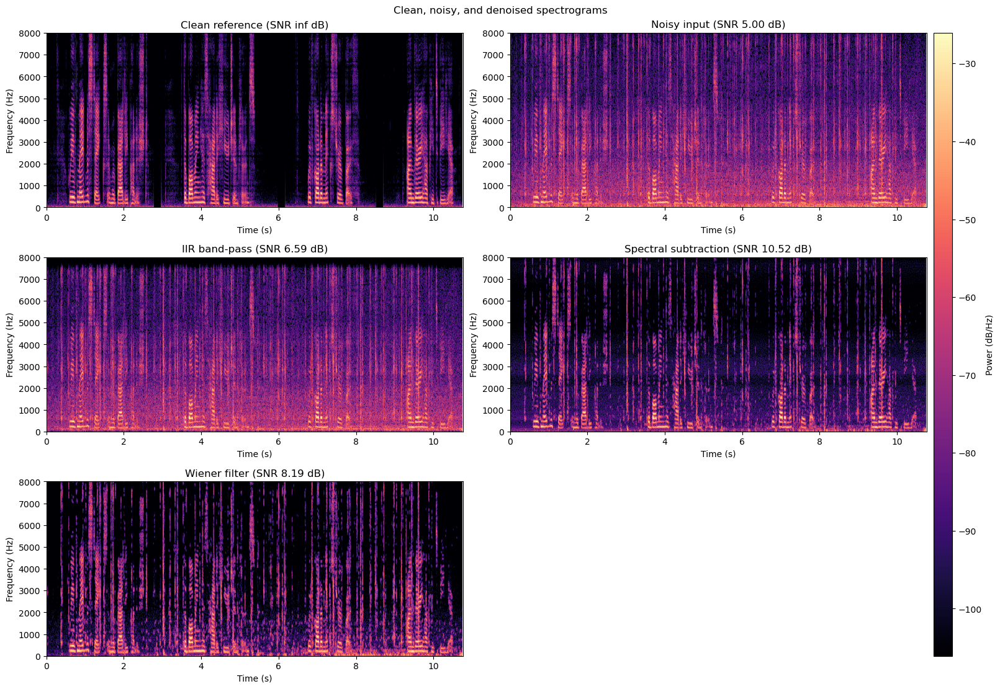

Listen at the same playback volume when comparing:
Noisy input


IIR band-pass


FIR band-pass


Spectral subtraction


Wiener filter


In [102]:
def measure_snr(reference, estimate):
    estimate = np.asarray(estimate)[:len(reference)]
    if len(estimate) != len(reference):
        raise ValueError("Reference and estimate must have the same number of samples")
    error_power = np.mean((estimate - reference) ** 2)
    if error_power == 0:
        return float("inf")
    return 10 * np.log10(np.mean(reference ** 2) / error_power)


input_snr_measured = measure_snr(clean, compatible_mixture)
method_outputs = {
    "Noisy input": compatible_mixture,
    "IIR band-pass": iir_filtered,
    "FIR band-pass": fir_filtered,
    "Spectral subtraction (estimated profile)": spectral_subtraction,
    "Wiener (estimated profile)": wiener_filtered,
    "Oracle spectral subtraction": oracle_spectral_subtraction,
    "Oracle Wiener": oracle_wiener,
}
method_snr = {name: measure_snr(clean, output) for name, output in method_outputs.items()}
print(f"Measured input SNR: {input_snr_measured:.2f} dB")
print("Method                                      Output SNR     Improvement")
print("-" * 72)
for name, score in method_snr.items():
    print(f"{name:<44} {score:>8.2f} dB   {score - input_snr_measured:>+8.2f} dB")

show_signals = [
    ("Clean reference", clean),
    ("Noisy input", compatible_mixture),
    ("IIR band-pass", iir_filtered),
    ("Spectral subtraction", spectral_subtraction),
    ("Wiener filter", wiener_filtered),
]
specs = []
for _, sample in show_signals:
    spec_freq, spec_time, spec_power = signal.spectrogram(
        sample, fs=fs_clean, window="hann", nperseg=512, noverlap=384, mode="psd"
    )
    specs.append((spec_freq, spec_time, 10 * np.log10(spec_power + 1e-12)))
color_max = max(float(np.max(spec)) for _, _, spec in specs)
color_min = color_max - 80
fig = plt.figure(figsize=(16, 11), layout="constrained")
grid = fig.add_gridspec(3, 3, width_ratios=(1, 1, 0.045))
plot_axes = [fig.add_subplot(grid[row, col]) for row in range(3) for col in range(2)]
colorbar_axis = fig.add_subplot(grid[:, 2])
for ax, (name, sample), (freq_axis, time_axis, spec) in zip(plot_axes, show_signals, specs):
    image = ax.pcolormesh(
        time_axis, freq_axis, spec, shading="auto",
        vmin=color_min, vmax=color_max, cmap="magma"
    )
    ax.set_title(f"{name} (SNR {measure_snr(clean, sample):.2f} dB)")
    ax.set_xlim(0, len(clean) / fs_clean)
    ax.set_ylim(0, fs_clean / 2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time (s)")
plot_axes[-1].set_visible(False)
fig.colorbar(image, cax=colorbar_axis, label="Power (dB/Hz)")
fig.suptitle("Clean, noisy, and denoised spectrograms")
plt.show()

print("Listen at the same playback volume when comparing:")
for name, sample in [
    ("Noisy input", compatible_mixture),
    ("IIR band-pass", iir_filtered),
    ("FIR band-pass", fir_filtered),
    ("Spectral subtraction", spectral_subtraction),
    ("Wiener filter", wiener_filtered),
]:
    print(name)
    ipd.display(ipd.Audio(sample, rate=fs_clean, normalize=False))

## Combined denoising pipeline

The methods above are shown separately so their individual effects can be compared. They can also be connected: first use a band-pass filter to reduce out-of-band rumble/hiss, then apply one STFT denoiser to target remaining noise that overlaps speech. Cascading every denoiser is not automatically better, because repeated suppression can remove speech detail.

The main combined method here is **FIR band-pass -> spectral subtraction**. The noise-reference recording is passed through the same FIR filter before its spectrum is estimated, so its profile matches the filtered input. IIR -> spectral subtraction and FIR -> Wiener are included as comparisons. The exact injected-noise cascade is an oracle benchmark for this simulation only; real recordings do not provide the exact noise waveform.

Standalone FIR SNR: 7.01 dB
Standalone spectral subtraction SNR: 10.52 dB
Combined pipeline                          Output SNR    Improvement vs input
----------------------------------------------------------------------------
Noisy input                                      5.00 dB          +0.00 dB
FIR -> spectral subtraction                     10.94 dB          +5.94 dB
IIR -> spectral subtraction                     10.83 dB          +5.83 dB
FIR -> Wiener                                    9.59 dB          +4.59 dB
Oracle FIR -> spectral subtraction              14.77 dB          +9.77 dB
FIR -> spectral subtraction change vs standalone spectral subtraction: +0.42 dB


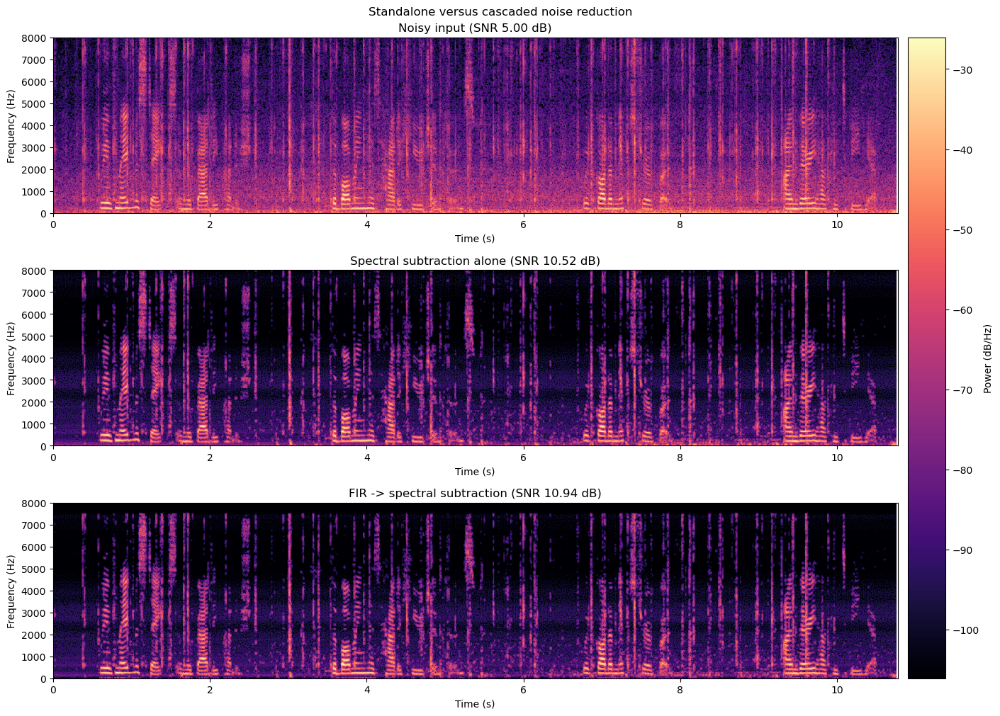

Listen at the same playback level:
Noisy input


Spectral subtraction alone


FIR followed by spectral subtraction


In [103]:
def stft_denoise_with_profile(noisy_signal, noise_reference, method):
    """Denoise using a separate noise reference processed through the same path."""
    _, _, noisy_transform = signal.stft(
        noisy_signal, fs=fs_clean, window=window_name,
        nperseg=frame_length, noverlap=frame_overlap,
        boundary="zeros", padded=True,
    )
    _, _, noise_transform = signal.stft(
        noise_reference, fs=fs_clean, window=window_name,
        nperseg=frame_length, noverlap=frame_overlap,
        boundary="zeros", padded=True,
    )
    magnitude = np.abs(noisy_transform)
    phase = np.exp(1j * np.angle(noisy_transform))
    noise_power_profile = np.mean(np.abs(noise_transform) ** 2, axis=1, keepdims=True)

    if method == "spectral subtraction":
        noise_magnitude_profile = np.sqrt(noise_power_profile)
        cleaned_magnitude = np.maximum(
            magnitude - ss_alpha * noise_magnitude_profile,
            ss_floor * noise_magnitude_profile,
        )
        cleaned_transform = cleaned_magnitude * phase
    elif method == "Wiener":
        gain = np.sqrt(
            np.maximum(magnitude ** 2 - noise_power_profile, 0.0)
            / (magnitude ** 2 + 1e-12)
        )
        gain = median_filter(gain, size=(3, 3))
        gain = np.maximum(gain, 0.05)
        cleaned_transform = magnitude * gain * phase
    else:
        raise ValueError(f"Unsupported denoising method: {method}")

    _, cleaned = signal.istft(
        cleaned_transform, fs=fs_clean, window=window_name,
        nperseg=frame_length, noverlap=frame_overlap, boundary=True,
    )
    cleaned = cleaned[:len(clean)]
    if len(cleaned) != len(clean) or not np.all(np.isfinite(cleaned)):
        raise ValueError("Denoising produced an invalid signal")
    return cleaned


# Filter both the mixture and its practical noise-reference recording identically.
fir_filtered_noise_reference = signal.filtfilt(fir_taps, [1.0], noise_profile_signal)
iir_filtered_noise_reference = signal.sosfiltfilt(iir_sos, noise_profile_signal)
fir_then_spectral_subtraction = stft_denoise_with_profile(
    fir_filtered, fir_filtered_noise_reference, "spectral subtraction"
)
iir_then_spectral_subtraction = stft_denoise_with_profile(
    iir_filtered, iir_filtered_noise_reference, "spectral subtraction"
)
fir_then_wiener = stft_denoise_with_profile(
    fir_filtered, fir_filtered_noise_reference, "Wiener"
)

# Oracle reference uses exact time-aligned noise from this synthetic mixture.
fir_filtered_oracle_noise = signal.filtfilt(fir_taps, [1.0], compatible_noise)
_, _, fir_pipeline_stft = signal.stft(
    fir_filtered, fs=fs_clean, window=window_name,
    nperseg=frame_length, noverlap=frame_overlap,
    boundary="zeros", padded=True,
)
_, _, fir_oracle_noise_stft = signal.stft(
    fir_filtered_oracle_noise, fs=fs_clean, window=window_name,
    nperseg=frame_length, noverlap=frame_overlap,
    boundary="zeros", padded=True,
)
fir_pipeline_magnitude = np.abs(fir_pipeline_stft)
fir_oracle_noise_magnitude = np.abs(fir_oracle_noise_stft)
fir_pipeline_phase = np.exp(1j * np.angle(fir_pipeline_stft))
fir_oracle_clean_magnitude = np.maximum(
    fir_pipeline_magnitude - ss_alpha * fir_oracle_noise_magnitude,
    ss_floor * fir_oracle_noise_magnitude,
)
_, fir_then_oracle_spectral_subtraction = signal.istft(
    fir_oracle_clean_magnitude * fir_pipeline_phase,
    fs=fs_clean, window=window_name,
    nperseg=frame_length, noverlap=frame_overlap, boundary=True,
)
fir_then_oracle_spectral_subtraction = fir_then_oracle_spectral_subtraction[:len(clean)]

combined_outputs = {
    "Noisy input": compatible_mixture,
    "FIR -> spectral subtraction": fir_then_spectral_subtraction,
    "IIR -> spectral subtraction": iir_then_spectral_subtraction,
    "FIR -> Wiener": fir_then_wiener,
    "Oracle FIR -> spectral subtraction": fir_then_oracle_spectral_subtraction,
}
combined_snr = {name: measure_snr(clean, output) for name, output in combined_outputs.items()}
print(f"Standalone FIR SNR: {measure_snr(clean, fir_filtered):.2f} dB")
print(f"Standalone spectral subtraction SNR: {measure_snr(clean, spectral_subtraction):.2f} dB")
print("Combined pipeline                          Output SNR    Improvement vs input")
print("-" * 76)
for name, score in combined_snr.items():
    print(f"{name:<44} {score:>8.2f} dB       {score - input_snr_measured:>+8.2f} dB")
print(
    "FIR -> spectral subtraction change vs standalone spectral subtraction: "
    f"{combined_snr['FIR -> spectral subtraction'] - measure_snr(clean, spectral_subtraction):+.2f} dB"
)

comparison_signals = [
    ("Noisy input", compatible_mixture),
    ("Spectral subtraction alone", spectral_subtraction),
    ("FIR -> spectral subtraction", fir_then_spectral_subtraction),
]
comparison_specs = []
for _, sample in comparison_signals:
    spec_freq, spec_time, spec_power = signal.spectrogram(
        sample, fs=fs_clean, window="hann", nperseg=512, noverlap=384, mode="psd"
    )
    comparison_specs.append((spec_freq, spec_time, 10 * np.log10(spec_power + 1e-12)))
comparison_max = max(float(np.max(item[2])) for item in comparison_specs)
comparison_min = comparison_max - 80
fig = plt.figure(figsize=(14, 10), layout="constrained")
grid = fig.add_gridspec(3, 2, width_ratios=(1, 0.045))
comparison_axes = [fig.add_subplot(grid[row, 0]) for row in range(3)]
comparison_colorbar_axis = fig.add_subplot(grid[:, 1])
for ax, (name, sample), (freq_axis, time_axis, spec) in zip(
    comparison_axes, comparison_signals, comparison_specs
):
    image = ax.pcolormesh(
        time_axis, freq_axis, spec, shading="auto",
        vmin=comparison_min, vmax=comparison_max, cmap="magma"
    )
    ax.set_title(f"{name} (SNR {measure_snr(clean, sample):.2f} dB)")
    ax.set_xlim(0, len(clean) / fs_clean)
    ax.set_ylim(0, fs_clean / 2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time (s)")
fig.colorbar(image, cax=comparison_colorbar_axis, label="Power (dB/Hz)")
fig.suptitle("Standalone versus cascaded noise reduction")
plt.show()

print("Listen at the same playback level:")
for name, sample in [
    ("Noisy input", compatible_mixture),
    ("Spectral subtraction alone", spectral_subtraction),
    ("FIR followed by spectral subtraction", fir_then_spectral_subtraction),
]:
    print(name)
    ipd.display(ipd.Audio(sample, rate=fs_clean, normalize=False))

## Targeted keyboard-click experiment

Keyboard clicks are short, impulsive events, so an average noise spectrum can dilute their contribution. In this controlled synthetic mixture, the injected noise segment is known and time-aligned. The detector below uses that noise-only segment to locate brief high-frequency bursts, then applies a smoothly faded, localized attenuation to the same frequency band in the mixture. This is **reference-assisted (oracle timing)**: it isolates the effect of click suppression, but it is not a blind detector that could be applied to an unknown speech recording. The experiment compares the unprocessed mixture, the existing FIR-to-spectral-subtraction pipeline, and versions with localized suppression. Overall SNR and high-frequency residual energy in the detected event windows are both reported; listen for speech artifacts as well.

Detected transient events: 24
Total event-window coverage: 9.9% of the recording
Click attenuation target in 1500-7500 Hz: -12.0 dB
Method                                             Overall SNR    Event-band reduction
-------------------------------------------------------------------------------------------
Noisy input                                            5.00 dB          0.00 dB
Localized click suppression                            5.37 dB          6.62 dB
FIR -> spectral subtraction                           10.94 dB          2.61 dB
Click suppression -> FIR -> spectral subtraction      11.56 dB          7.00 dB


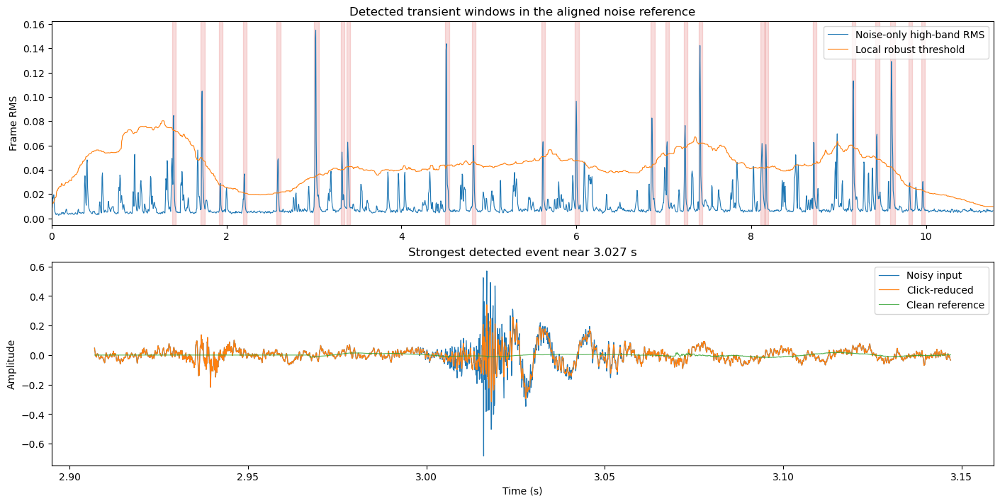

Listen at the same playback volume:
Noisy input


FIR -> spectral subtraction


Click suppression -> FIR -> spectral subtraction


In [104]:
from scipy.ndimage import binary_closing, label, gaussian_filter1d, median_filter

click_band_low_hz = 1500.0
click_band_high_hz = min(7500.0, fs_clean / 2 - 100.0)
if click_band_high_hz <= click_band_low_hz:
    raise ValueError("The sampling rate is too low for the selected click-detection band")
click_band_sos = signal.butter(
    4, [click_band_low_hz, click_band_high_hz], btype="bandpass",
    fs=fs_clean, output="sos"
)
noise_click_band = signal.sosfiltfilt(click_band_sos, compatible_noise)
mixture_click_band = signal.sosfiltfilt(click_band_sos, compatible_mixture)

click_frame_length = int(round(0.010 * fs_clean))
click_hop_length = int(round(0.005 * fs_clean))
if len(noise_click_band) < click_frame_length:
    raise ValueError("The noise segment is too short for transient analysis")
noise_frames = np.lib.stride_tricks.sliding_window_view(
    noise_click_band, click_frame_length
)[::click_hop_length]
click_frame_rms = np.sqrt(np.mean(noise_frames ** 2, axis=1))
local_window_frames = max(3, int(round(1.0 * fs_clean / click_hop_length)) | 1)
click_local_median = median_filter(
    click_frame_rms, size=local_window_frames, mode="nearest"
)
click_local_mad = median_filter(
    np.abs(click_frame_rms - click_local_median),
    size=local_window_frames, mode="nearest"
)
click_local_scale = 1.4826 * click_local_mad
click_scale_floor = max(
    float(np.median(click_local_scale)) * 0.1, np.finfo(float).eps
)
click_score = (click_frame_rms - click_local_median) / np.maximum(
    click_local_scale, click_scale_floor
)
click_score_threshold = 15.0
click_candidates = click_score > click_score_threshold
edge_frames = int(round(0.05 * fs_clean / click_hop_length))
click_candidates[:edge_frames] = False
click_candidates[-edge_frames:] = False
click_candidates = binary_closing(click_candidates, structure=np.ones(3, dtype=bool))
click_labels, click_label_count = label(click_candidates)
click_events = []
for event_label in range(1, click_label_count + 1):
    event_frames = np.flatnonzero(click_labels == event_label)
    if event_frames.size < 2:
        continue
    peak_frame = event_frames[np.argmax(click_score[event_frames])]
    click_events.append((
        int(event_frames[0]), int(event_frames[-1]), float(click_score[peak_frame])
    ))
if not click_events:
    raise RuntimeError("No transient events detected; lower click_score_threshold and rerun")

event_support = np.zeros(len(compatible_mixture), dtype=float)
click_event_times = []
for first_frame, last_frame, peak_score in click_events:
    event_start = max(0, first_frame * click_hop_length - int(round(0.006 * fs_clean)))
    event_stop = min(
        len(event_support), last_frame * click_hop_length + click_frame_length
        + int(round(0.020 * fs_clean))
    )
    event_support[event_start:event_stop] = 1.0
    click_event_times.append((event_start / fs_clean, event_stop / fs_clean, peak_score))
click_gain_envelope = gaussian_filter1d(
    event_support, sigma=max(1.0, 0.003 * fs_clean)
)
click_target_gain = 0.25
click_reduced_mixture = compatible_mixture - (
    1.0 - click_target_gain
) * click_gain_envelope * mixture_click_band

click_fir_filtered = signal.filtfilt(fir_taps, [1.0], click_reduced_mixture)
click_then_fir_then_spectral_subtraction = stft_denoise_with_profile(
    click_fir_filtered, fir_filtered_noise_reference, "spectral subtraction"
)

def click_window_band_power(estimate):
    residual = np.asarray(estimate)[:len(clean)] - clean
    residual_band = signal.sosfiltfilt(click_band_sos, residual)
    return float(np.sum((event_support * residual_band) ** 2))

click_reference_power = click_window_band_power(compatible_mixture)
click_comparison_outputs = {
    "Noisy input": compatible_mixture,
    "Localized click suppression": click_reduced_mixture,
    "FIR -> spectral subtraction": fir_then_spectral_subtraction,
    "Click suppression -> FIR -> spectral subtraction":
        click_then_fir_then_spectral_subtraction,
}
print(f"Detected transient events: {len(click_events)}")
print(f"Total event-window coverage: {event_support.mean() * 100:.1f}% of the recording")
print(f"Click attenuation target in {click_band_low_hz:.0f}-{click_band_high_hz:.0f} Hz: "
      f"{20 * np.log10(click_target_gain):.1f} dB")
print("Method                                             Overall SNR    Event-band reduction")
print("-" * 91)
for name, estimate in click_comparison_outputs.items():
    snr = measure_snr(clean, estimate)
    event_power = click_window_band_power(estimate)
    event_reduction = 10 * np.log10(click_reference_power / max(event_power, 1e-30))
    print(f"{name:<51} {snr:>7.2f} dB       {event_reduction:>7.2f} dB")

click_frame_times = (
    np.arange(len(click_frame_rms)) * click_hop_length + click_frame_length / 2
) / fs_clean
click_threshold_curve = click_local_median + click_score_threshold * np.maximum(
    click_local_scale, click_scale_floor
)
strongest_event = max(click_event_times, key=lambda event: event[2])
zoom_center = (strongest_event[0] + strongest_event[1]) / 2
zoom_half_width = 0.12
zoom_start = max(0, int((zoom_center - zoom_half_width) * fs_clean))
zoom_stop = min(len(clean), int((zoom_center + zoom_half_width) * fs_clean))
zoom_time = np.arange(zoom_start, zoom_stop) / fs_clean
fig, click_axes = plt.subplots(2, 1, figsize=(14, 7), layout="constrained")
click_axes[0].plot(click_frame_times, click_frame_rms, label="Noise-only high-band RMS", lw=0.8)
click_axes[0].plot(click_frame_times, click_threshold_curve, label="Local robust threshold", lw=0.8)
for event_start, event_stop, _ in click_event_times:
    click_axes[0].axvspan(event_start, event_stop, color="tab:red", alpha=0.16)
click_axes[0].set_xlim(0, len(clean) / fs_clean)
click_axes[0].set_ylabel("Frame RMS")
click_axes[0].set_title("Detected transient windows in the aligned noise reference")
click_axes[0].legend(loc="upper right")
click_axes[1].plot(zoom_time, compatible_mixture[zoom_start:zoom_stop], label="Noisy input", lw=0.9)
click_axes[1].plot(zoom_time, click_reduced_mixture[zoom_start:zoom_stop], label="Click-reduced", lw=0.9)
click_axes[1].plot(zoom_time, clean[zoom_start:zoom_stop], label="Clean reference", lw=0.8, alpha=0.8)
click_axes[1].set_xlabel("Time (s)")
click_axes[1].set_ylabel("Amplitude")
click_axes[1].set_title(f"Strongest detected event near {zoom_center:.3f} s")
click_axes[1].legend(loc="upper right")
plt.show()

print("Listen at the same playback volume:")
for name, estimate in [
    ("Noisy input", compatible_mixture),
    ("FIR -> spectral subtraction", fir_then_spectral_subtraction),
    ("Click suppression -> FIR -> spectral subtraction",
     click_then_fir_then_spectral_subtraction),
]:
    print(name)
    ipd.display(ipd.Audio(estimate, rate=fs_clean, normalize=False))

## Reusable denoising function for unknown recordings

The best-performing tested chain was **FIR band-pass -> spectral subtraction**. This function adds a conservative, localized click attenuator before that chain. Unlike the preceding controlled click experiment, it detects transients from the noisy recording itself and does not receive or use clean speech. By default, it estimates a noise spectrum from the quietest 20% of frames in the recording; this can mistake quiet speech for noise or miss noise that changes over time. For better calibration, optionally pass a separate noise-only recording made at a similar gain and in the same acoustic conditions. Click detection can also flag sharp speech consonants, so inspect and listen to the result rather than assuming it is artifact-free.

The returned audio is mono floating-point at the input sample rate. The diagnostics report the detection count, event windows, and noise-profile source. The demonstration below processes a noisy recording without loading or passing a clean reference; replace its file path with another recording to try it on new audio. If you have a separate noise-only recording, supply it as `noise_reference` (and its rate if different):

```python
noise_rate, noise_only = wavfile.read("./audio/noise_recording.wav")
result, details = denoise_unknown_audio(noisy_audio, noisy_rate, noise_only, noise_rate)
```

A noise-only reference should be captured at a similar gain; this function does not infer a gain match from speech.

In [105]:
import numpy as np
from scipy import signal
from scipy.ndimage import binary_closing, gaussian_filter1d, label, median_filter

def denoise_unknown_audio(
    noisy_audio,
    sample_rate,
    noise_reference=None,
    noise_sample_rate=None,
    click_threshold=15.0,
    click_attenuation=0.25,
    noise_frame_percentile=20.0,
    subtraction_strength=1.2,
    spectral_floor=0.05,
):
    """Reduce broadband noise and transient clicks without a clean reference.

    If no noise_reference is supplied, estimate the noise spectrum from the
    quietest frames of the noisy input. A supplied noise_reference must be a
    separate noise-only recording captured at a comparable recording gain.
    Returns (mono_float_audio, diagnostics).
    """
    def as_float_mono(audio, name):
        audio = np.asarray(audio)
        if audio.ndim == 2:
            audio = audio.mean(axis=1)
        elif audio.ndim != 1:
            raise ValueError(f"{name} must be mono or have shape (samples, channels)")
        if not np.issubdtype(audio.dtype, np.number):
            raise TypeError(f"{name} must contain numeric samples")
        if np.issubdtype(audio.dtype, np.integer):
            limits = np.iinfo(audio.dtype)
            audio = audio.astype(np.float64) / max(abs(limits.min), limits.max)
        else:
            audio = audio.astype(np.float64)
        if audio.size == 0 or not np.all(np.isfinite(audio)):
            raise ValueError(f"{name} must be non-empty and contain only finite samples")
        return audio

    if not isinstance(sample_rate, (int, np.integer)) or sample_rate <= 0:
        raise ValueError("sample_rate must be a positive integer in Hz")
    if click_threshold <= 0:
        raise ValueError("click_threshold must be positive")
    if not 0.0 <= click_attenuation <= 1.0:
        raise ValueError("click_attenuation must be between 0 and 1")
    if not 0.0 < noise_frame_percentile <= 100.0:
        raise ValueError("noise_frame_percentile must be in (0, 100]")
    if subtraction_strength < 0 or not 0.0 <= spectral_floor <= 1.0:
        raise ValueError("subtraction_strength must be non-negative and spectral_floor in [0, 1]")

    fs = int(sample_rate)
    audio = as_float_mono(noisy_audio, "noisy_audio")
    if len(audio) < 64:
        raise ValueError("noisy_audio must contain at least 64 samples")

    nyquist = fs / 2.0
    low_cutoff_hz = min(70.0, nyquist * 0.02)
    high_cutoff_hz = min(7500.0, nyquist - 100.0)
    if not 0.0 < low_cutoff_hz < high_cutoff_hz:
        raise ValueError("sample_rate is too low for the speech band-pass filter")
    fir_taps = signal.firwin(
        401, [low_cutoff_hz, high_cutoff_hz],
        pass_zero="bandpass", fs=fs, window="hamming",
    )

    click_low_hz = min(1500.0, nyquist * 0.35)
    click_high_hz = min(7500.0, nyquist - 100.0)
    click_events = []
    click_mask = np.zeros(len(audio), dtype=np.float64)
    if click_low_hz < click_high_hz:
        click_sos = signal.butter(
            4, [click_low_hz, click_high_hz], btype="bandpass", fs=fs, output="sos"
        )
        high_band = signal.sosfiltfilt(click_sos, audio)
        frame_length = min(len(audio), max(16, int(round(0.010 * fs))))
        hop_length = max(1, int(round(0.005 * fs)))
        frames = np.lib.stride_tricks.sliding_window_view(high_band, frame_length)[::hop_length]
        frame_rms = np.sqrt(np.mean(frames ** 2, axis=1))
        requested_window = max(3, int(round(fs / hop_length)) | 1)
        largest_odd_window = len(frame_rms) if len(frame_rms) % 2 else len(frame_rms) - 1
        local_window = min(requested_window, largest_odd_window)
        if local_window >= 3:
            local_median = median_filter(frame_rms, size=local_window, mode="nearest")
            local_mad = median_filter(
                np.abs(frame_rms - local_median), size=local_window, mode="nearest"
            ) * 1.4826
            scale_floor = max(float(np.median(local_mad)) * 0.1, np.finfo(float).eps)
            transient_score = (frame_rms - local_median) / np.maximum(local_mad, scale_floor)
            candidates = transient_score > click_threshold
            candidates = binary_closing(candidates, structure=np.ones(3, dtype=bool))
            event_labels, event_count = label(candidates)
            for event_label in range(1, event_count + 1):
                event_frames = np.flatnonzero(event_labels == event_label)
                if event_frames.size < 2:
                    continue
                event_start = max(
                    0, int(event_frames[0] * hop_length - round(0.006 * fs))
                )
                event_stop = min(
                    len(audio),
                    int(event_frames[-1] * hop_length + frame_length + round(0.020 * fs)),
                )
                click_mask[event_start:event_stop] = 1.0
                peak_score = float(np.max(transient_score[event_frames]))
                click_events.append((event_start / fs, event_stop / fs, peak_score))
        click_envelope = gaussian_filter1d(
            click_mask, sigma=max(1.0, 0.003 * fs)
        )
        click_reduced = audio - (1.0 - click_attenuation) * click_envelope * high_band
    else:
        click_reduced = audio.copy()

    filtered_audio = signal.filtfilt(
        fir_taps, [1.0], click_reduced,
        padlen=min(3 * (len(fir_taps) - 1), len(click_reduced) - 1),
    )
    frame_length = min(512, 2 ** int(np.floor(np.log2(len(filtered_audio)))))
    if frame_length < 32:
        raise ValueError("Audio is too short for STFT spectral subtraction")
    overlap = int(frame_length * 0.75)
    window = "hann"

    def stft_and_noise_profile(samples):
        if len(samples) < frame_length:
            raise ValueError("Noise reference is too short for the selected STFT frame length")
        _, _, transform = signal.stft(
            samples, fs=fs, window=window, nperseg=frame_length,
            noverlap=overlap, boundary="zeros", padded=True,
        )
        frame_energy = np.mean(np.abs(transform) ** 2, axis=0)
        cutoff = np.percentile(frame_energy, noise_frame_percentile)
        quiet_frames = frame_energy <= cutoff
        if not np.any(quiet_frames):
            quiet_frames[np.argmin(frame_energy)] = True
        profile_power = np.mean(np.abs(transform[:, quiet_frames]) ** 2, axis=1, keepdims=True)
        return transform, profile_power

    noisy_transform, estimated_noise_power = stft_and_noise_profile(filtered_audio)
    if noise_reference is None:
        noise_power = estimated_noise_power
        profile_source = "quietest frames of noisy input"
        reference_resampled = False
    else:
        reference = as_float_mono(noise_reference, "noise_reference")
        reference_rate = fs if noise_sample_rate is None else noise_sample_rate
        if not isinstance(reference_rate, (int, np.integer)) or reference_rate <= 0:
            raise ValueError("noise_sample_rate must be a positive integer in Hz")
        reference_resampled = int(reference_rate) != fs
        if reference_resampled:
            divisor = int(np.gcd(fs, int(reference_rate)))
            reference = signal.resample_poly(
                reference, fs // divisor, int(reference_rate) // divisor
            )
        reference_filtered = signal.filtfilt(
            fir_taps, [1.0], reference,
            padlen=min(3 * (len(fir_taps) - 1), len(reference) - 1),
        )
        _, noise_power = stft_and_noise_profile(reference_filtered)
        profile_source = "separate noise-only reference"

    magnitude = np.abs(noisy_transform)
    phase = np.exp(1j * np.angle(noisy_transform))
    noise_magnitude = np.sqrt(noise_power)
    cleaned_transform = np.maximum(
        magnitude - subtraction_strength * noise_magnitude,
        spectral_floor * noise_magnitude,
    ) * phase
    _, cleaned = signal.istft(
        cleaned_transform, fs=fs, window=window, nperseg=frame_length,
        noverlap=overlap, boundary=True,
    )
    cleaned = cleaned[:len(audio)]
    if len(cleaned) != len(audio) or not np.all(np.isfinite(cleaned)):
        raise RuntimeError("Denoising produced an invalid or non-finite waveform")

    diagnostics = {
        "sample_rate": fs,
        "noise_profile_source": profile_source,
        "noise_reference_resampled": reference_resampled,
        "click_event_count": len(click_events),
        "click_event_windows_seconds": click_events,
        "click_mask_coverage_percent": 100.0 * float(np.mean(click_mask)),
        "click_band_hz": (click_low_hz, click_high_hz),
        "speech_band_hz": (low_cutoff_hz, high_cutoff_hz),
    }
    return cleaned, diagnostics

## Batch test on the ten noisy recordings

This section processes every WAV in `noisy_audio/` twice: with the function defaults and with stronger spectral subtraction. It reports input/output RMS levels and detected transient-window counts, and plots per-file level changes plus median spectra across files. The files do not match the available clean speech reference, so these are **not SNR scores** and a lower RMS alone does not prove better speech quality. Detected transients are also candidates, not verified clicks. Listen to the examples and check for speech damage before drawing conclusions. The HCI recording is kept separate in the final experiment below.

In [ ]:
from pathlib import Path
from scipy.io import wavfile
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

noisy_audio_folder = Path("noisy_audio")
if not noisy_audio_folder.is_dir():
    raise FileNotFoundError(f"No noisy-audio folder found at: {noisy_audio_folder.resolve()}")
noisy_audio_files = sorted(
    noisy_audio_folder.glob("*.wav"),
    key=lambda path: int(path.stem.split("_")[-1])
    if path.stem.split("_")[-1].isdigit() else path.name.lower(),
)
if not noisy_audio_files:
    raise FileNotFoundError(f"No WAV files found in {noisy_audio_folder.resolve()}")


def audio_rms_dbfs(samples):
    samples = np.asarray(samples)
    if samples.ndim == 2:
        samples = samples.mean(axis=1)
    if np.issubdtype(samples.dtype, np.integer):
        limits = np.iinfo(samples.dtype)
        samples = samples.astype(float) / max(abs(limits.min), limits.max)
    else:
        samples = samples.astype(float)
    return 20 * np.log10(max(float(np.sqrt(np.mean(samples ** 2))), 1e-12))


batch_results = []
batch_spectra = {"Input": [], "Default": [], "Stronger": []}
batch_frequencies = None
for audio_path in noisy_audio_files:
    sample_rate, noisy_samples = wavfile.read(audio_path)
    default_output, default_info = denoise_unknown_audio(noisy_samples, sample_rate)
    stronger_output, stronger_info = denoise_unknown_audio(
        noisy_samples,
        sample_rate,
        noise_frame_percentile=30.0,
        subtraction_strength=2.0,
        spectral_floor=0.01,
    )
    if len(default_output) != len(noisy_samples) or len(stronger_output) != len(noisy_samples):
        raise RuntimeError(f"Denoiser changed the sample count for {audio_path.name}")
    if not np.all(np.isfinite(default_output)) or not np.all(np.isfinite(stronger_output)):
        raise RuntimeError(f"Denoiser returned non-finite samples for {audio_path.name}")

    input_level = audio_rms_dbfs(noisy_samples)
    default_level = audio_rms_dbfs(default_output)
    stronger_level = audio_rms_dbfs(stronger_output)
    batch_results.append({
        "file": audio_path.name,
        "sample_rate": sample_rate,
        "duration_seconds": len(noisy_samples) / sample_rate,
        "input_rms_dbfs": input_level,
        "default_rms_dbfs": default_level,
        "default_level_change_db": default_level - input_level,
        "strong_rms_dbfs": stronger_level,
        "strong_level_change_db": stronger_level - input_level,
        "default_click_candidates": default_info["click_event_count"],
        "strong_click_candidates": stronger_info["click_event_count"],
    })

    plot_input = np.asarray(noisy_samples)
    if plot_input.ndim == 2:
        plot_input = plot_input.mean(axis=1)
    if np.issubdtype(plot_input.dtype, np.integer):
        limits = np.iinfo(plot_input.dtype)
        plot_input = plot_input.astype(float) / max(abs(limits.min), limits.max)
    else:
        plot_input = plot_input.astype(float)
    plot_outputs = {
        "Input": plot_input,
        "Default": default_output,
        "Stronger": stronger_output,
    }
    current_frequency = None
    for series_name, samples in plot_outputs.items():
        frequencies, power = signal.welch(
            samples, fs=sample_rate, window="hann",
            nperseg=min(4096, len(samples)), scaling="density",
        )
        if current_frequency is not None and not np.array_equal(frequencies, current_frequency):
            raise ValueError("All batch files must share a sampling rate and comparable Welch grids")
        current_frequency = frequencies
        batch_spectra[series_name].append(10 * np.log10(power + 1e-15))
    if batch_frequencies is None:
        batch_frequencies = current_frequency
    elif not np.array_equal(batch_frequencies, current_frequency):
        raise ValueError("All batch files must share the same sampling rate for aggregate spectra")

print(f"Processed {len(batch_results)} WAV files from {noisy_audio_folder.resolve()}")
print("RMS changes are level differences, not SNR improvements.")
print("File         fs (Hz) Duration   Input RMS   Default RMS  Change   Strong RMS  Change  Click candidates")
print("-" * 111)
for result in batch_results:
    print(
        f"{result['file']:<12} {result['sample_rate']:>7} "
        f"{result['duration_seconds']:>7.2f}s "
        f"{result['input_rms_dbfs']:>9.2f} dBFS "
        f"{result['default_rms_dbfs']:>9.2f} dBFS "
        f"{result['default_level_change_db']:>+6.2f} dB "
        f"{result['strong_rms_dbfs']:>9.2f} dBFS "
        f"{result['strong_level_change_db']:>+6.2f} dB "
        f"{result['default_click_candidates']:>3}/{result['strong_click_candidates']:<3}"
    )

file_labels = [result["file"] for result in batch_results]
x_positions = np.arange(len(file_labels))
fig, (level_ax, spectrum_ax) = plt.subplots(
    2, 1, figsize=(14, 9), layout="constrained"
)
bar_width = 0.38
level_ax.bar(
    x_positions - bar_width / 2,
    [-result["default_level_change_db"] for result in batch_results],
    width=bar_width, label="Default",
)
level_ax.bar(
    x_positions + bar_width / 2,
    [-result["strong_level_change_db"] for result in batch_results],
    width=bar_width, label="Stronger",
)
level_ax.axhline(0, color="black", linewidth=0.8)
level_ax.set_xticks(x_positions)
level_ax.set_xticklabels(file_labels, rotation=45, ha="right")
level_ax.set_ylabel("Input RMS minus output RMS (dB)")
level_ax.set_title("Per-file RMS level reduction (not SNR)")
level_ax.grid(True, axis="y", alpha=0.3)
level_ax.legend()

for series_name, spectra in batch_spectra.items():
    median_spectrum = np.median(np.vstack(spectra), axis=0)
    spectrum_ax.plot(batch_frequencies, median_spectrum, label=series_name, linewidth=1.2)
spectrum_ax.set_xlim(0, min(8000, batch_results[0]["sample_rate"] / 2))
spectrum_ax.set_xlabel("Frequency (Hz)")
spectrum_ax.set_ylabel("Median power spectral density (dB/Hz)")
spectrum_ax.set_title("Median spectrum across the ten files")
spectrum_ax.grid(True, alpha=0.3)
spectrum_ax.legend()
plt.show()

## Conclusion from the ten-file test

The denoiser successfully processed all ten WAV files at 22.05 kHz. The stronger settings lowered the output RMS more than the default settings for most files, but barely changed `noisy_5.wav`. The number of detected transient candidates also varied considerably between files. This suggests the recordings do not all respond in the same way, and a single setting may not work equally well for every noise condition.

These results show changes in signal level and spectrum, **not measured noise-removal quality**. The files are not aligned with the available clean speech reference, so SNR improvement cannot be calculated; lower RMS could mean noise was reduced, speech was attenuated, or both. The click detector reports candidates, which may include speech sounds rather than actual clicks. Listen to the original and processed files at matched loudness before judging them. For a stronger conclusion, repeat the comparison with noisy mixtures made from a known clean reference, then report SNR improvement for each noise type and level. The HCI recording is a separate real-audio demonstration without an objective clean-reference score.

Selected output diagnostics:
sample_rate: 44100
noise_profile_source: quietest frames of noisy input
noise_reference_resampled: False
click_event_count: 17
click_event_windows_seconds: [(1.2062358276643992, 1.247233560090703, 18.842695646908027), (5.960430839002267, 6.001428571428572, 15.210083973777209), (7.0429705215419505, 7.088956916099773, 18.246612984132014), (9.582199546485262, 9.673083900226757, 24.14355124063686), (23.226190476190474, 23.322063492063492, 26.63154741814772), (25.101927437641724, 25.14292517006803, 16.093051380433014), (34.39580498866213, 34.43680272108843, 16.965839381262803), (34.535487528344675, 34.60641723356009, 48.33843516268188), (35.55816326530612, 35.61412698412698, 19.247216737074996), (42.432539682539684, 42.49349206349206, 16.14123984375769), (43.91417233560091, 44.03498866213152, 30.496773644155738), (50.683786848072565, 50.74972789115646, 25.805232358110096), (61.28469387755102, 61.370589569161, 58.58931356934458), (61.444331065759634, 61.535215419

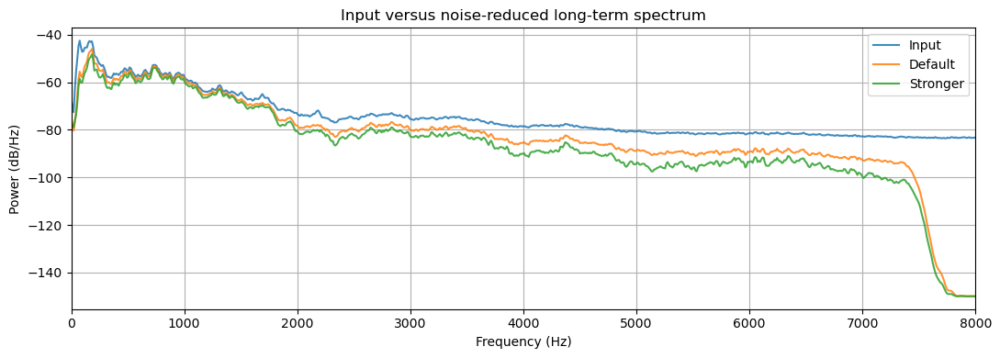

Listen to each version with playback normalization for a fair comparison:
Original


Default denoising


Stronger stationary-noise suppression


In [107]:
from scipy.io import wavfile
import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# This HCI recording is used only for this final unknown-audio experiment.
# Replace the path below to test a different noisy WAV file.
unknown_audio_path = "hci_audio_record.wav"
unknown_sample_rate, unknown_audio = wavfile.read(unknown_audio_path)

# Compare the speech-preserving defaults with stronger stationary-noise suppression.
unknown_default, default_diagnostics = denoise_unknown_audio(
    unknown_audio, unknown_sample_rate
)
unknown_denoised, unknown_diagnostics = denoise_unknown_audio(
    unknown_audio,
    unknown_sample_rate,
    noise_frame_percentile=30.0,
    subtraction_strength=2.0,
    spectral_floor=0.01,
)

# Optional: set this to a segment you have listened to and confirmed contains
# background noise only. Leave it as None to use automatic estimation.
noise_reference_start_seconds = None
noise_reference_duration_seconds = 2.0
if noise_reference_start_seconds is not None:
    start = int(noise_reference_start_seconds * unknown_sample_rate)
    stop = int(
        (noise_reference_start_seconds + noise_reference_duration_seconds)
        * unknown_sample_rate
    )
    if start < 0 or stop > len(unknown_audio) or stop <= start:
        raise ValueError("The selected noise-only interval is outside the recording")
    noise_only_reference = unknown_audio[start:stop]
    unknown_denoised, unknown_diagnostics = denoise_unknown_audio(
        unknown_audio,
        unknown_sample_rate,
        noise_reference=noise_only_reference,
        noise_sample_rate=unknown_sample_rate,
        subtraction_strength=2.0,
        spectral_floor=0.01,
    )

print("Selected output diagnostics:")
for key, value in unknown_diagnostics.items():
    print(f"{key}: {value}")

def to_float_mono_for_plot(samples):
    samples = np.asarray(samples)
    if samples.ndim == 2:
        samples = samples.mean(axis=1)
    if np.issubdtype(samples.dtype, np.integer):
        limits = np.iinfo(samples.dtype)
        samples = samples.astype(float) / max(abs(limits.min), limits.max)
    else:
        samples = samples.astype(float)
    return samples

unknown_audio_float = to_float_mono_for_plot(unknown_audio)
def rms_dbfs(samples):
    samples = to_float_mono_for_plot(samples)
    return 20 * np.log10(max(np.sqrt(np.mean(samples ** 2)), 1e-12))

print(f"Input RMS: {rms_dbfs(unknown_audio):.1f} dBFS")
print(f"Default output RMS: {rms_dbfs(unknown_default):.1f} dBFS")
print(f"Stronger output RMS: {rms_dbfs(unknown_denoised):.1f} dBFS")
print("RMS is a level measure, not SNR; this unknown recording has no clean reference.")

# Compare long-term spectra to see which frequency bands still contain steady noise.
plot_nperseg = min(4096, len(unknown_audio_float))
plt.figure(figsize=(11, 4))
for label, samples in [
    ("Input", unknown_audio_float),
    ("Default", unknown_default),
    ("Stronger", unknown_denoised),
]:
    frequencies, power = signal.welch(
        samples, fs=unknown_sample_rate, nperseg=plot_nperseg
    )
    plt.plot(frequencies, 10 * np.log10(power + 1e-15), label=label, alpha=0.85)
plt.xlim(0, min(8000, unknown_sample_rate / 2))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB/Hz)")
plt.title("Input versus noise-reduced long-term spectrum")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Listen to each version with playback normalization for a fair comparison:")
for label, samples in [
    ("Original", unknown_audio),
    ("Default denoising", unknown_default),
    ("Stronger stationary-noise suppression", unknown_denoised),
]:
    print(label)
    ipd.display(ipd.Audio(samples, rate=unknown_sample_rate, normalize=True))

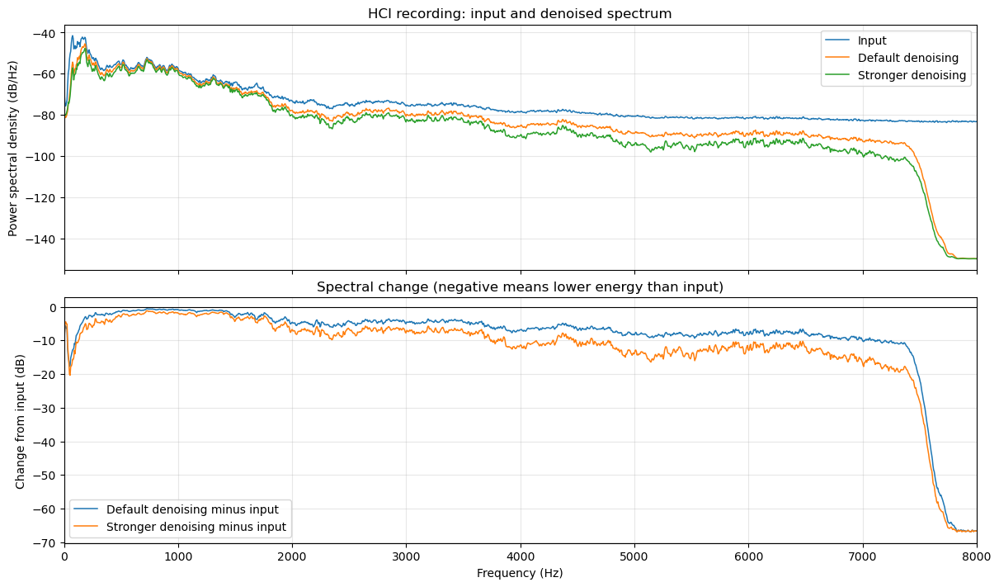

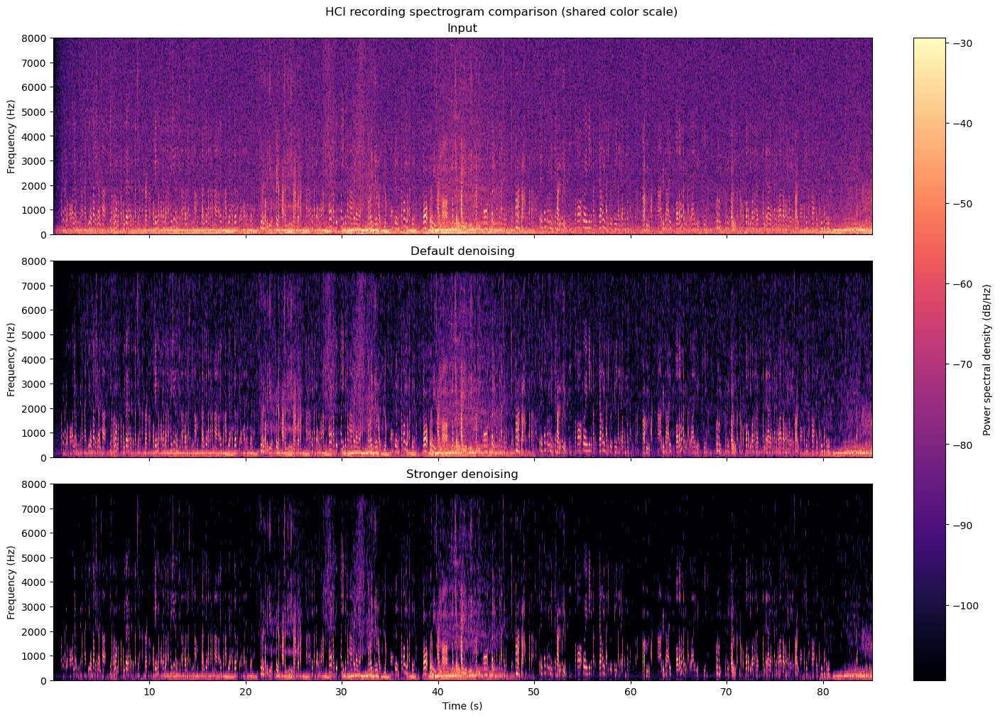

In [108]:
# Independent spectrum comparison for the final HCI experiment.
# Run the HCI experiment cell above first to create these waveforms.
if "unknown_audio" not in globals() or "unknown_default" not in globals() or "unknown_denoised" not in globals():
    raise RuntimeError("Run the HCI experiment cell above before plotting its spectra.")

spectrum_signals = [
    ("Input", unknown_audio_float),
    ("Default denoising", unknown_default),
    ("Stronger denoising", unknown_denoised),
]
plot_nperseg = min(8192, len(unknown_audio_float))
spectrum_results = {}
for name, samples in spectrum_signals:
    frequencies, power = signal.welch(
        samples, fs=unknown_sample_rate, window="hann",
        nperseg=plot_nperseg, noverlap=plot_nperseg // 2,
        scaling="density",
    )
    spectrum_results[name] = 10 * np.log10(power + 1e-15)

fig, (spectrum_ax, reduction_ax) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, layout="constrained"
)
for name, spectrum_db in spectrum_results.items():
    spectrum_ax.plot(frequencies, spectrum_db, label=name, linewidth=1.1)
spectrum_ax.set_ylabel("Power spectral density (dB/Hz)")
spectrum_ax.set_title("HCI recording: input and denoised spectrum")
spectrum_ax.grid(True, alpha=0.3)
spectrum_ax.legend()

for name in ("Default denoising", "Stronger denoising"):
    reduction_ax.plot(
        frequencies,
        spectrum_results[name] - spectrum_results["Input"],
        label=f"{name} minus input",
        linewidth=1.1,
    )
reduction_ax.axhline(0, color="black", linewidth=0.8)
reduction_ax.set_xlim(0, min(8000, unknown_sample_rate / 2))
reduction_ax.set_xlabel("Frequency (Hz)")
reduction_ax.set_ylabel("Change from input (dB)")
reduction_ax.set_title("Spectral change (negative means lower energy than input)")
reduction_ax.grid(True, alpha=0.3)
reduction_ax.legend()
plt.show()
# Compare time-frequency structure with one shared color scale.
spectrogram_nperseg = 1024
spectrogram_noverlap = 768
spectrogram_results = {}
for name, samples in spectrum_signals:
    frequencies_stft, times_stft, power_stft = signal.spectrogram(
        samples, fs=unknown_sample_rate, window="hann",
        nperseg=spectrogram_nperseg, noverlap=spectrogram_noverlap,
        scaling="density", mode="psd",
    )
    spectrogram_results[name] = 10 * np.log10(power_stft + 1e-15)

shared_max = max(float(np.max(spec)) for spec in spectrogram_results.values())
shared_min = shared_max - 80.0
fig, spectrogram_axes = plt.subplots(
    3, 1, figsize=(14, 10), sharex=True, sharey=True,
    layout="constrained",
)
for ax, (name, spectrum_db) in zip(spectrogram_axes, spectrogram_results.items()):
    image = ax.pcolormesh(
        times_stft, frequencies_stft, spectrum_db,
        shading="auto", cmap="magma", vmin=shared_min, vmax=shared_max,
    )
    ax.set_title(name)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, min(8000, unknown_sample_rate / 2))
spectrogram_axes[-1].set_xlabel("Time (s)")
fig.colorbar(image, ax=spectrogram_axes, label="Power spectral density (dB/Hz)")
fig.suptitle("HCI recording spectrogram comparison (shared color scale)")
plt.show()
